# Introduction to Machine Learning with PyTorch
## Project: Finding Donors for *CharityML*

Welcome to the first project of the Data Scientist Nanodegree! In this notebook, some template code has already been provided for you, and it will be your job to implement the additional functionality necessary to successfully complete this project. Sections that begin with **'Implementation'** in the header indicate that the following block of code will require additional functionality which you must provide. Instructions will be provided for each section and the specifics of the implementation are marked in the code block with a `TODO` statement. Please be sure to read the instructions carefully!

In addition to implementing code, there will be questions that you must answer which relate to the project and your implementation. Each section where you will answer a question is preceded by a **'Question X'** header. Carefully read each question and provide thorough answers in the following text boxes that begin with **'Answer:'**. Your project submission will be evaluated based on your answers to each of the questions and the implementation you provide.  

>**Note:** Please specify **WHICH VERSION OF PYTHON** you are using when submitting this notebook. Code and Markdown cells can be executed using the **Shift + Enter** keyboard shortcut. In addition, Markdown cells can be edited by typically double-clicking the cell to enter edit mode.

> **Python version used for this submission:** Python 3.14.7, with NumPy 2.5.1, pandas 3.0.6, scikit-learn 1.9.1 and matplotlib 3.11.2.

## Getting Started

In this project, you will employ several supervised algorithms of your choice to accurately model individuals' income using data collected from the 1994 U.S. Census. You will then choose the best candidate algorithm from preliminary results and further optimize this algorithm to best model the data. Your goal with this implementation is to construct a model that accurately predicts whether an individual makes more than $50,000. This sort of task can arise in a non-profit setting, where organizations survive on donations.  Understanding an individual's income can help a non-profit better understand how large of a donation to request, or whether or not they should reach out to begin with.  While it can be difficult to determine an individual's general income bracket directly from public sources, we can (as we will see) infer this value from other publically available features. 

The dataset for this project originates from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Census+Income). The datset was donated by Ron Kohavi and Barry Becker, after being published in the article _"Scaling Up the Accuracy of Naive-Bayes Classifiers: A Decision-Tree Hybrid"_. You can find the article by Ron Kohavi [online](https://www.aaai.org/Papers/KDD/1996/KDD96-033.pdf). The data we investigate here consists of small changes to the original dataset, such as removing the `fnlwgt` feature and records with missing or ill-formatted entries.

----
## Exploring the Data
Run the code cell below to load necessary Python libraries and load the census data. Note that the last column from this dataset, `income`, will be our target label (whether an individual makes more than, or at most, $50,000 annually). All other columns are features about each individual in the census database.

In [1]:
# Import libraries necessary for this project
import numpy as np
import pandas as pd
from time import time
from IPython.display import display # Allows the use of display() for DataFrames

# Import supplementary visualization code visuals.py
import visuals as vs

# Pretty display for notebooks
%matplotlib inline

# Load the Census dataset
data = pd.read_csv("census.csv")

# Success - Display the first record
display(data.head(n=1))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K


### Implementation: Data Exploration
A cursory investigation of the dataset will determine how many individuals fit into either group, and will tell us about the percentage of these individuals making more than \$50,000. In the code cell below, you will need to compute the following:
- The total number of records, `n_records`
- The number of individuals making more than \$50,000 annually, `n_greater_50k`.
- The number of individuals making at most \$50,000 annually, `n_at_most_50k`.
- The percentage of individuals making more than \$50,000 annually, `greater_percent`.

**HINT:** You may need to look at the table above to understand how the `income` entries are formatted. 

In [2]:
# TODO: Total number of records
n_records = data.shape[0]

# TODO: Number of records where individual's income is more than $50,000
n_greater_50k = int((data['income'].str.strip() == '>50K').sum())

# TODO: Number of records where individual's income is at most $50,000
n_at_most_50k = int((data['income'].str.strip() == '<=50K').sum())

# TODO: Percentage of individuals whose income is more than $50,000
greater_percent = round(100.0 * n_greater_50k / n_records, 2)

# Print the results
print("Total number of records: {}".format(n_records))
print("Individuals making more than $50,000: {}".format(n_greater_50k))
print("Individuals making at most $50,000: {}".format(n_at_most_50k))
print("Percentage of individuals making more than $50,000: {}%".format(greater_percent))


Total number of records: 45222
Individuals making more than $50,000: 11208
Individuals making at most $50,000: 34014
Percentage of individuals making more than $50,000: 24.78%


**Featureset Exploration**

* **age**: continuous. 
* **workclass**: Private, Self-emp-not-inc, Self-emp-inc, Federal-gov, Local-gov, State-gov, Without-pay, Never-worked. 
* **education**: Bachelors, Some-college, 11th, HS-grad, Prof-school, Assoc-acdm, Assoc-voc, 9th, 7th-8th, 12th, Masters, 1st-4th, 10th, Doctorate, 5th-6th, Preschool. 
* **education-num**: continuous. 
* **marital-status**: Married-civ-spouse, Divorced, Never-married, Separated, Widowed, Married-spouse-absent, Married-AF-spouse. 
* **occupation**: Tech-support, Craft-repair, Other-service, Sales, Exec-managerial, Prof-specialty, Handlers-cleaners, Machine-op-inspct, Adm-clerical, Farming-fishing, Transport-moving, Priv-house-serv, Protective-serv, Armed-Forces. 
* **relationship**: Wife, Own-child, Husband, Not-in-family, Other-relative, Unmarried. 
* **race**: Black, White, Asian-Pac-Islander, Amer-Indian-Eskimo, Other. 
* **sex**: Female, Male. 
* **capital-gain**: continuous. 
* **capital-loss**: continuous. 
* **hours-per-week**: continuous. 
* **native-country**: United-States, Cambodia, England, Puerto-Rico, Canada, Germany, Outlying-US(Guam-USVI-etc), India, Japan, Greece, South, China, Cuba, Iran, Honduras, Philippines, Italy, Poland, Jamaica, Vietnam, Mexico, Portugal, Ireland, France, Dominican-Republic, Laos, Ecuador, Taiwan, Haiti, Columbia, Hungary, Guatemala, Nicaragua, Scotland, Thailand, Yugoslavia, El-Salvador, Trinadad&Tobago, Peru, Hong, Holand-Netherlands.

----
## Preparing the Data
Before data can be used as input for machine learning algorithms, it often must be cleaned, formatted, and restructured — this is typically known as **preprocessing**. Fortunately, for this dataset, there are no invalid or missing entries we must deal with, however, there are some qualities about certain features that must be adjusted. This preprocessing can help tremendously with the outcome and predictive power of nearly all learning algorithms.

### Transforming Skewed Continuous Features
A dataset may sometimes contain at least one feature whose values tend to lie near a single number, but will also have a non-trivial number of vastly larger or smaller values than that single number.  Algorithms can be sensitive to such distributions of values and can underperform if the range is not properly normalized. With the census dataset two features fit this description: `capital-gain` and `capital-loss`. 

Run the code cell below to plot a histogram of these two features. Note the range of the values present and how they are distributed.

C:\udacity\Introduction-to-ML\Udacity_Introduction-to-ML-with-Pytorch_P1_Finding_Donors\starter\visuals.py:50: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


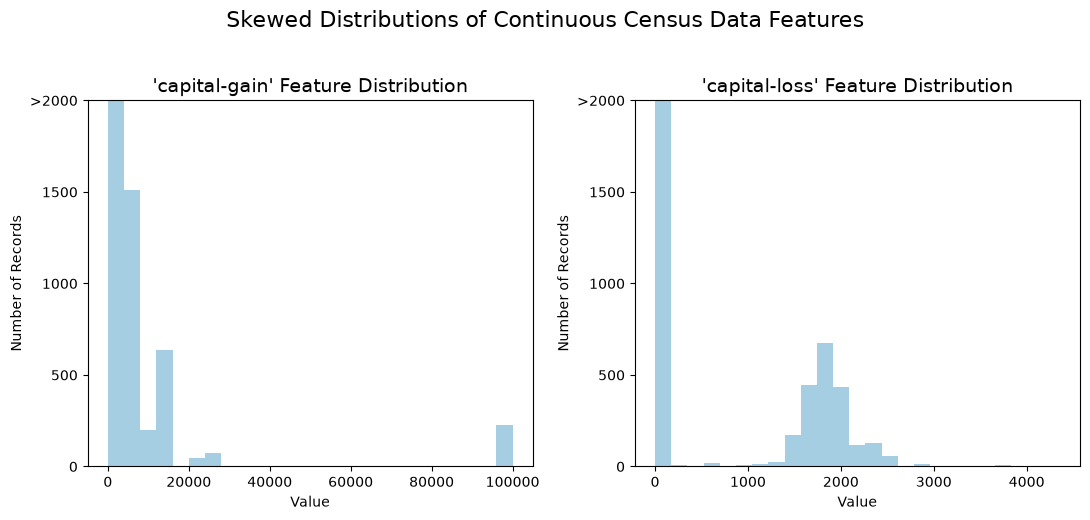

In [3]:
# Split the data into features and target label
income_raw = data['income']
features_raw = data.drop('income', axis = 1)

# Visualize skewed continuous features of original data
vs.distribution(data)

For highly-skewed feature distributions such as `capital-gain` and `capital-loss`, it is common practice to apply a [logarithmic transformation](https://en.wikipedia.org/wiki/Data_transformation_(statistics)) on the data so that the very large and very small values do not negatively affect the performance of a learning algorithm. Using a logarithmic transformation significantly reduces the range of values caused by outliers. Care must be taken when applying this transformation however: The logarithm of 0 is undefined, so we must translate the values by a small amount above 0 to apply the the logarithm successfully.

Run the code cell below to perform a transformation on the data and visualize the results. Again, note the range of values and how they are distributed. 

C:\udacity\Introduction-to-ML\Udacity_Introduction-to-ML-with-Pytorch_P1_Finding_Donors\starter\visuals.py:50: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


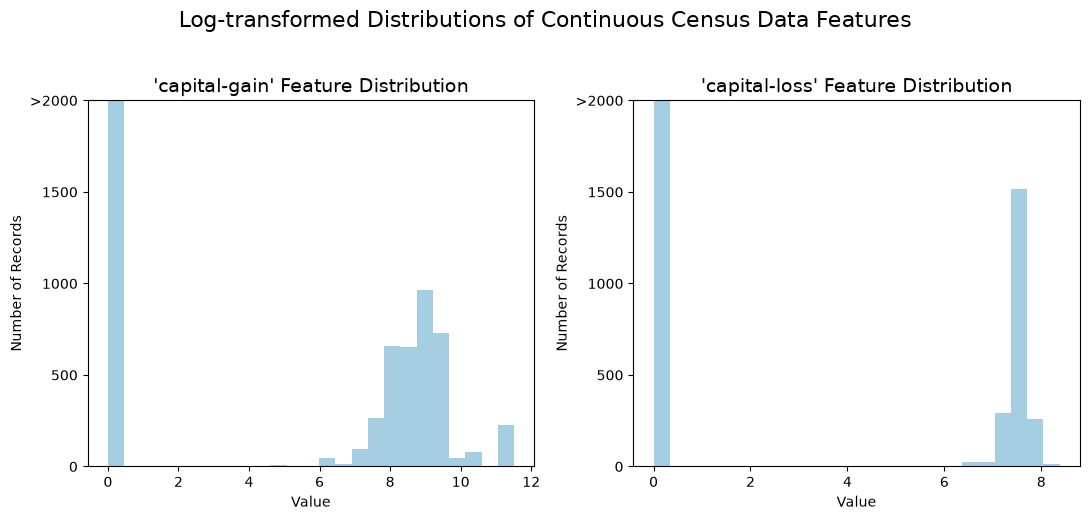

In [4]:
# Log-transform the skewed features
skewed = ['capital-gain', 'capital-loss']
features_log_transformed = pd.DataFrame(data = features_raw)
features_log_transformed[skewed] = features_raw[skewed].apply(lambda x: np.log(x + 1))

# Visualize the new log distributions
vs.distribution(features_log_transformed, transformed = True)

### Normalizing Numerical Features
In addition to performing transformations on features that are highly skewed, it is often good practice to perform some type of scaling on numerical features. Applying a scaling to the data does not change the shape of each feature's distribution (such as `capital-gain` or `capital-loss` above); however, normalization ensures that each feature is treated equally when applying supervised learners. Note that once scaling is applied, observing the data in its raw form will no longer have the same original meaning, as exampled below.

Run the code cell below to normalize each numerical feature. We will use [`sklearn.preprocessing.MinMaxScaler`](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) for this.

In [5]:
# Import sklearn.preprocessing.StandardScaler
from sklearn.preprocessing import MinMaxScaler

# Initialize a scaler, then apply it to the features
scaler = MinMaxScaler() # default=(0, 1)
numerical = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

features_log_minmax_transform = pd.DataFrame(data = features_log_transformed)
features_log_minmax_transform[numerical] = scaler.fit_transform(features_log_transformed[numerical])

# Show an example of a record with scaling applied
display(features_log_minmax_transform.head(n = 5))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,0.301370,State-gov,Bachelors,0.800000,Never-married,Adm-clerical,Not-in-family,White,Male,0.667492,0.0,0.397959,United-States
1,0.452055,Self-emp-not-inc,Bachelors,0.800000,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.000000,0.0,0.122449,United-States
2,0.287671,Private,HS-grad,0.533333,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.000000,0.0,0.397959,United-States
3,0.493151,Private,11th,0.400000,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.000000,0.0,0.397959,United-States
4,0.150685,Private,Bachelors,0.800000,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.000000,0.0,0.397959,Cuba


### Implementation: Data Preprocessing

From the table in **Exploring the Data** above, we can see there are several features for each record that are non-numeric. Typically, learning algorithms expect input to be numeric, which requires that non-numeric features (called *categorical variables*) be converted. One popular way to convert categorical variables is by using the **one-hot encoding** scheme. One-hot encoding creates a _"dummy"_ variable for each possible category of each non-numeric feature. For example, assume `someFeature` has three possible entries: `A`, `B`, or `C`:

|   | someFeature |                    
| :-: | :-: |                            
| 0 |  B  |  
| 1 |  C  |
| 2 |  A  |  

We then encode this feature into `someFeature_A`, `someFeature_B` and `someFeature_C`:

|| someFeature_A | someFeature_B | someFeature_C |
| :-: | :-: | :-: | :-: |
|0| 0 | 1 | 0 |
|1| 0 | 0 | 1 |
|2| 1 | 0 | 0 |

Additionally, as with the non-numeric features, we need to convert the non-numeric target label, `income` to numerical values for the learning algorithm to work. Since there are only two possible categories for this label ("<=50K" and ">50K"), we can avoid using one-hot encoding and simply encode these two categories as 0 and 1, respectively. In code cell below, you will need to implement the following:
 - Use [`pandas.get_dummies()`](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.get_dummies.html?highlight=get_dummies#pandas.get_dummies) to perform one-hot encoding on the `features_log_minmax_transform` data.
 - Convert the target label `income_raw` to numerical entries.
   - Set records with "<=50K" to 0 and records with ">50K" to 1.

In [6]:
# TODO: One-hot encode the 'features_log_minmax_transform' data using pandas.get_dummies()
features_final = pd.get_dummies(features_log_minmax_transform)

# TODO: Encode the 'income_raw' data to numerical values
# Values are '<=50K' and '>50K' (strip whitespace defensively), mapped to 0 and 1.
income = (income_raw.str.strip() == '>50K').astype(int)

# Print the number of features after one-hot encoding
encoded = list(features_final.columns)
print("{} total features after one-hot encoding.".format(len(encoded)))

# Uncomment the following line to see the encoded feature names
# print(encoded)


103 total features after one-hot encoding.


### Shuffle and Split Data
Now all _categorical variables_ have been converted into numerical features, and all numerical features have been normalized. As always, we will now split the data (both features and their labels) into training and test sets. 80% of the data will be used for training and 20% for testing.

Run the code cell below to perform this split.

In [7]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the 'features' and 'income' data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features_final, 
                                                    income, 
                                                    test_size = 0.2, 
                                                    random_state = 0)

# Show the results of the split
print("Training set has {} samples.".format(X_train.shape[0]))
print("Testing set has {} samples.".format(X_test.shape[0]))

Training set has 36177 samples.
Testing set has 9045 samples.


----
## Evaluating Model Performance
In this section, we will investigate four different algorithms, and determine which is best at modeling the data. Three of these algorithms will be supervised learners of your choice, and the fourth algorithm is known as a *naive predictor*.

### Metrics and the Naive Predictor

*CharityML*, equipped with their research, knows individuals that make more than \$50,000 are most likely to donate to their charity. Because of this, *CharityML* is particularly interested in predicting who makes more than \$50,000 accurately. It would seem that using **accuracy** as a metric for evaluating a particular model's performace would be appropriate. Additionally, identifying someone that *does not* make more than \$50,000 as someone who does would be detrimental to *CharityML*, since they are looking to find individuals willing to donate. Therefore, a model's ability to precisely predict those that make more than \$50,000 is *more important* than the model's ability to **recall** those individuals. We can use **F-beta score** as a metric that considers both precision and recall:

$$ F_{\beta} = (1 + \beta^2) \cdot \frac{\text{precision} \cdot \text{recall}}{\left( \beta^2 \cdot \text{precision} \right) + \text{recall}} $$

In particular, when $\beta = 0.5$, more emphasis is placed on precision. This is called the $F_{0.5}$ score (or F-score for simplicity).

Looking at the distribution of classes (those who make at most \\$50,000, and those who make more), it's clear most individuals do not make more than \$50,000. This can greatly affect **accuracy**, since we could simply say *"this person does not make more than \$50,000"* and generally be right, without ever looking at the data! Making such a statement would be called **naive**, since we have not considered any information to substantiate the claim. It is always important to consider the *naive prediction* for your data, to help establish a benchmark for whether a model is performing well. That been said, using that prediction would be pointless: If we predicted all people made less than \$50,000, *CharityML* would identify no one as donors. 


#### Note: Recap of accuracy, precision, recall

**Accuracy** measures how often the classifier makes the correct prediction. It’s the ratio of the number of correct predictions to the total number of predictions (the number of test data points).

**Precision** tells us what proportion of messages we classified as spam, actually were spam.
It is a ratio of true positives (words classified as spam, and which are actually spam) to all positives (all words classified as spam, irrespective of whether that was the correct classificatio), in other words it is the ratio of

$$\text{Precision} = \frac{\text{True Positives}} {\text{True Positives} + \text{False Positives}}$$

**Recall (sensitivity)** tells us what proportion of messages that actually were spam were classified by us as spam.
It is a ratio of true positives (words classified as spam, and which are actually spam) to all the words that were actually spam, in other words it is the ratio of

$$\text{Recall} = \frac{\text{True Positives}} {\text{True Positives} + \text{False Negatives}}$$

For classification problems that are skewed in their classification distributions, like in our case, for example, if we had 100 text messages and only 2 were spam and the remaining 98 weren't, accuracy is not a very good metric. We could classify 90 messages as not spam (including the 2 that were spam, but we classify them as not spam, hence they would be false negatives) and 10 as spam (all 10 false positives) and still get a reasonably good accuracy score. For such cases, precision and recall come in very handy. These two metrics can be combined to get the F1 score and the weighted average (harmonic mean) of the precision and recall scores. This score can range from 0 to 1, with 1 being the best possible F1 score(we take the harmonic mean when dealing with ratios).

### Question 1 - Naive Predictor Performace
* If we chose a model that always predicted an individual made more than $50,000, what would  that model's accuracy and F-score be on this dataset? You must use the code cell below and assign your results to `accuracy` and `fscore` to be used later.

**Please note** that the the purpose of generating a naive predictor is simply to show what a base model without any intelligence would look like. In the real world, ideally your base model would be either the results of a previous model or could be based on a research paper upon which you are looking to improve. When there is no benchmark model set, getting a result better than random choice is a place you could start from.

**HINT:** 

* When we have a model that always predicts 1 (i.e., the individual makes more than 50k) then our model will have no True Negatives (TN) or False Negatives (FN) as we are not making any negative (0 value) predictions. Therefore our Accuracy in this case becomes the same as our Precision (True Positives / (True Positives + False Positives)) as every prediction that we have made with value 1 that should have 0 becomes a False Positive; therefore our denominator in this case is the total number of records we have in total. 
* Our Recall score (True Positives / (True Positives + False Negatives)) in this setting becomes 1 as we have no False Negatives.

In [8]:
TP = np.sum(income) # Counting the ones as this is the naive case. Note that 'income' is the 'income_raw' data encoded to numerical values done in the data preprocessing step.
FP = income.count() - TP # Specific to the naive case

TN = 0 # No predicted negatives in the naive case
FN = 0 # No predicted negatives in the naive case

# TODO: Calculate accuracy, precision and recall
accuracy = TP / (TP + FP)   # = n_greater_50k / n_records
precision = TP / (TP + FP)  # Same as accuracy in this naive case
recall = 1.0                # No false negatives: every record is predicted as '>50K'

# TODO: Calculate F-score using the formula above for beta = 0.5 and correct values for precision and recall.
beta = 0.5
fscore = (1 + beta ** 2) * (precision * recall) / ((beta ** 2 * precision) + recall)

# Print the results
print("Naive Predictor: [Accuracy score: {:.4f}, F-score: {:.4f}]".format(accuracy, fscore))


Naive Predictor: [Accuracy score: 0.2478, F-score: 0.2917]


###  Supervised Learning Models
**The following are some of the supervised learning models that are currently available in** [scikit-learn](http://scikit-learn.org/stable/supervised_learning.html) **that you may choose from:**
- Gaussian Naive Bayes (GaussianNB)
- Decision Trees
- Ensemble Methods (Bagging, AdaBoost, Random Forest, Gradient Boosting)
- K-Nearest Neighbors (KNeighbors)
- Stochastic Gradient Descent Classifier (SGDC)
- Support Vector Machines (SVM)
- Logistic Regression

### Question 2 - Model Application
List three of the supervised learning models above that are appropriate for this problem that you will test on the census data. For each model chosen

- Describe one real-world application in industry where the model can be applied. 
- What are the strengths of the model; when does it perform well?
- What are the weaknesses of the model; when does it perform poorly?
- What makes this model a good candidate for the problem, given what you know about the data?

**HINT:**

Structure your answer in the same format as above^, with 4 parts for each of the three models you pick. Please include references with your answer.

**Answer:**

The three supervised learning models I selected to test on the census data are the **Gradient Boosting Classifier**, the **Random Forest Classifier**, and **Logistic Regression**.

**1. Gradient Boosting Classifier** (`sklearn.ensemble.GradientBoostingClassifier`)

- **Real-world application:** Gradient boosting on decision trees is one of the most widely used algorithms for scoring on structured/tabular data. Industrial examples include credit-risk and credit-fraud scoring at banks, churn prediction in telecommunications, and click-through-rate (CTR) prediction used to rank search results and online advertisements.
- **Strengths:** It typically delivers state-of-the-art accuracy on tabular classification problems; it captures non-linear relationships and feature interactions automatically; it is invariant to feature scaling and tolerant of outliers; it performs well on imbalanced classes when combined with an appropriate metric (such as the F<sub>0.5</sub> score used here); and it exposes `feature_importances_` for interpretation.
- **Weaknesses:** Trees are built sequentially, so training is slower than bagging methods and does not trivially parallelize; it has several hyperparameters (`n_estimators`, `learning_rate`, `max_depth`) that must be tuned carefully; and with too many estimators or too deep a tree it can overfit the training data.
- **Why it suits this dataset:** After one-hot encoding, the census data mixes normalized numeric features (age, education-num, hours-per-week) with many binary categorical indicators, and the relationship between these features and income is clearly non-linear (e.g. income rises with age but plateaus, and capital-gain matters mostly when it is non-zero). Gradient boosting models these interactions directly, handles the ~75%/25% class skew better than a linear model, and should give the highest predictive F-score on this problem.

**2. Random Forest Classifier** (`sklearn.ensemble.RandomForestClassifier`)

- **Real-world application:** Random forests are commonly used for fraud detection in financial transactions, for medical diagnosis/patient risk stratification, and for feature selection in genomics, where many correlated measurements must be ranked by importance.
- **Strengths:** It averages many decorrelated decision trees, which gives low variance and makes it hard to overfit by simply adding trees; it requires very little tuning to be competitive; it handles high-dimensional data and mixed feature types well; it is robust to outliers and unscaled features; trees can be grown in parallel with `n_jobs`; and it provides feature importances (including a permutation-based one that is less biased than impurity importance).
- **Weaknesses:** Impurity-based importances are biased toward high-cardinality features; probability estimates tend to be less sharp than gradient boosting's; it generally plateaus at slightly lower accuracy than a well-tuned gradient boosting model; and storing many large trees is memory-hungry.
- **Why it suits this dataset:** It is a strong, robust baseline for a data set with 100+ one-hot columns and noisy categorical values, it trains quickly in parallel, and its resistance to overfitting makes it a useful control to check whether gradient boosting's gains are real rather than an artifact of a single model family.

**3. Logistic Regression** (`sklearn.linear_model.LogisticRegression`)

- **Real-world application:** Logistic regression is the standard workhorse for binary risk scoring: credit approval/credit-default models, medical outcome prediction (e.g. probability of disease), and classic email spam filtering.
- **Strengths:** It is very fast to train and to score; its coefficients are directly interpretable as log-odds, which matters when stakeholders must understand *why* someone is predicted to be a high earner; it outputs well-defined class probabilities; it has few hyperparameters and low variance, so it rarely overfits badly on data of this size.
- **Weaknesses:** It assumes a linear decision boundary, so it cannot capture non-linear effects or feature interactions without manual feature engineering; it is sensitive to multicollinearity among the dummy variables; and it usually underperforms ensemble methods on problems with complex structure like this one.
- **Why it suits this dataset:** The features have already been log-transformed and min-max normalized, which is close to ideal input for logistic regression, so it serves as a fast, interpretable benchmark. Including it tells CharityML how much accuracy is gained by paying the extra computational cost of the two ensemble models.

**References:**

- scikit-learn User Guide, *Ensembles of decision trees* (Random Forests and Gradient Boosting): https://scikit-learn.org/stable/modules/ensemble.html
- scikit-learn User Guide, *Generalized Linear Models* (Logistic Regression): https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
- scikit-learn API: `GradientBoostingClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html
- scikit-learn API: `RandomForestClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- scikit-learn API: `LogisticRegression`: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- Friedman, J. H. (2001). *Greedy Function Approximation: A Gradient Boosting Machine.* Annals of Statistics 29(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- Breiman, L. (2001). *Random Forests.* Machine Learning 45(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Kohavi, R. (1996). *Scaling Up the Accuracy of Naive-Bayes Classifiers: A Decision-Tree Hybrid.* Proceedings of KDD-96. https://www.aaai.org/Papers/KDD/1996/KDD96-033.pdf


### Implementation - Creating a Training and Predicting Pipeline
To properly evaluate the performance of each model you've chosen, it's important that you create a training and predicting pipeline that allows you to quickly and effectively train models using various sizes of training data and perform predictions on the testing data. Your implementation here will be used in the following section.
In the code block below, you will need to implement the following:
 - Import `fbeta_score` and `accuracy_score` from [`sklearn.metrics`](http://scikit-learn.org/stable/modules/classes.html#sklearn-metrics-metrics).
 - Fit the learner to the sampled training data and record the training time.
 - Perform predictions on the test data `X_test`, and also on the first 300 training points `X_train[:300]`.
   - Record the total prediction time.
 - Calculate the accuracy score for both the training subset and testing set.
 - Calculate the F-score for both the training subset and testing set.
   - Make sure that you set the `beta` parameter!

In [9]:
# TODO: Import two metrics from sklearn - fbeta_score and accuracy_score
from sklearn.metrics import fbeta_score, accuracy_score

def train_predict(learner, sample_size, X_train, y_train, X_test, y_test):
    '''
    inputs:
       - learner: the learning algorithm to be trained and predicted on
       - sample_size: the size of samples (number) to be drawn from training set
       - X_train: features training set
       - y_train: income training set
       - X_test: features testing set
       - y_test: income testing set
    '''

    results = {}

    # TODO: Fit the learner to the training data using slicing with 'sample_size' using .fit(training_features[:], training_labels[:])
    start = time() # Get start time
    learner = learner.fit(X_train[:sample_size], y_train[:sample_size])
    end = time() # Get end time

    # TODO: Calculate the training time
    results['train_time'] = end - start

    # TODO: Get the predictions on the test set(X_test),
    #       then get predictions on the first 300 training samples(X_train) using .predict()
    start = time() # Get start time
    predictions_test = learner.predict(X_test)
    predictions_train = learner.predict(X_train[:300])
    end = time() # Get end time

    # TODO: Calculate the total prediction time
    results['pred_time'] = end - start

    # TODO: Compute accuracy on the first 300 training samples which is y_train[:300]
    results['acc_train'] = accuracy_score(y_train[:300], predictions_train)

    # TODO: Compute accuracy on test set using accuracy_score()
    results['acc_test'] = accuracy_score(y_test, predictions_test)

    # TODO: Compute F-score on the the first 300 training samples using fbeta_score()
    results['f_train'] = fbeta_score(y_train[:300], predictions_train, beta = 0.5)

    # TODO: Compute F-score on the test set which is y_test
    results['f_test'] = fbeta_score(y_test, predictions_test, beta = 0.5)

    # Success
    print("{} trained on {} samples.".format(learner.__class__.__name__, sample_size))

    # Return the results
    return results


### Implementation: Initial Model Evaluation
In the code cell, you will need to implement the following:
- Import the three supervised learning models you've discussed in the previous section.
- Initialize the three models and store them in `clf_A`, `clf_B`, and `clf_C`.
  - Use a `random_state` for each model you use, if provided.
  - **Note:** Use the default settings for each model — you will tune one specific model in a later section.
- Calculate the number of records equal to 1%, 10%, and 100% of the training data.
  - Store those values in `samples_1`, `samples_10`, and `samples_100` respectively.

**Note:** Depending on which algorithms you chose, the following implementation may take some time to run!

GradientBoostingClassifier trained on 361 samples.


GradientBoostingClassifier trained on 3617 samples.


GradientBoostingClassifier trained on 36177 samples.
RandomForestClassifier trained on 361 samples.


RandomForestClassifier trained on 3617 samples.


RandomForestClassifier trained on 36177 samples.
LogisticRegression trained on 361 samples.
LogisticRegression trained on 3617 samples.


LogisticRegression trained on 36177 samples.


C:\udacity\Introduction-to-ML\Udacity_Introduction-to-ML-with-Pytorch_P1_Finding_Donors\starter\visuals.py:122: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  pl.tight_layout()


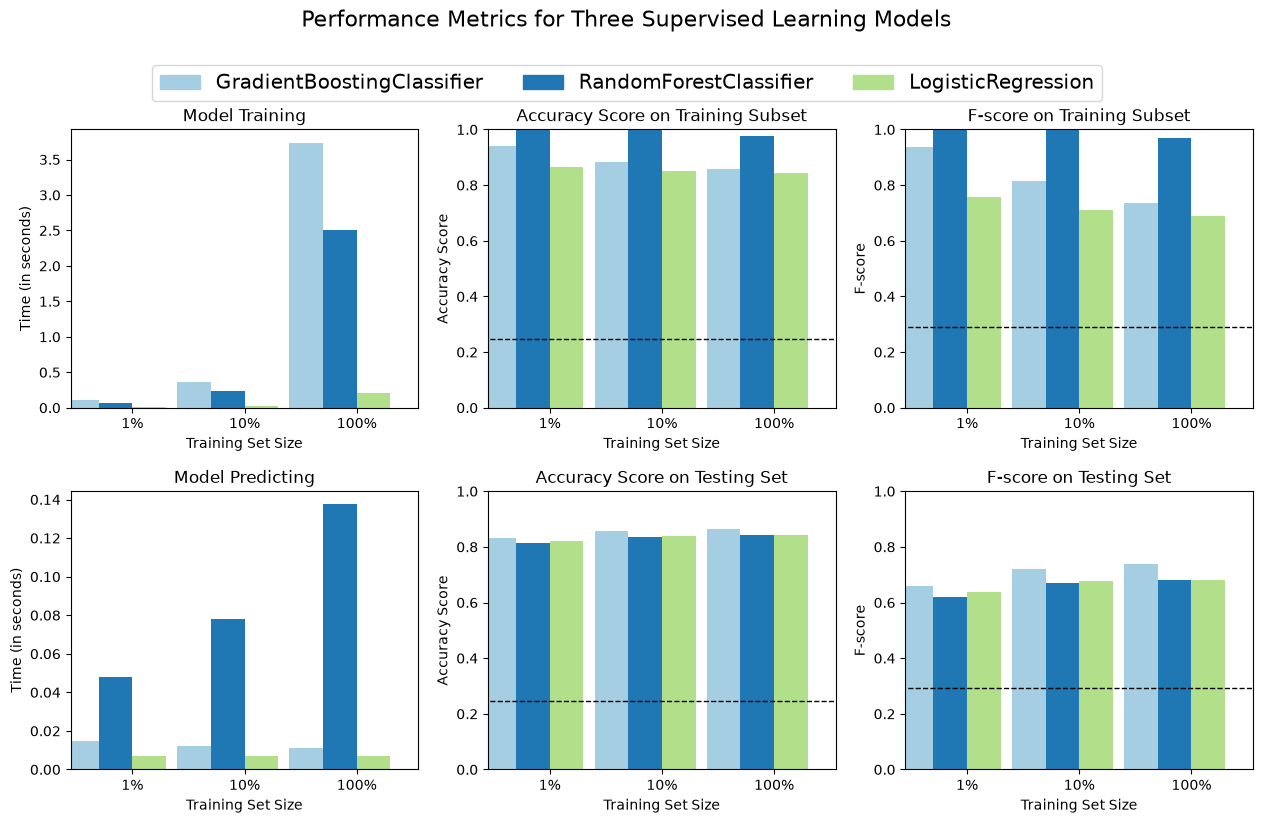

In [10]:
# TODO: Import the three supervised learning models from sklearn
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# TODO: Initialize the three models
clf_A = GradientBoostingClassifier(random_state=42)
clf_B = RandomForestClassifier(random_state=42)
clf_C = LogisticRegression(random_state=42, max_iter=1000)

# TODO: Calculate the number of samples for 1%, 10%, and 100% of the training data
# HINT: samples_100 is the entire training set i.e. len(y_train)
# HINT: samples_10 is 10% of samples_100 (ensure to set the count of the values to be `int` and not `float`)
# HINT: samples_1 is 1% of samples_100 (ensure to set the count of the values to be `int` and not `float`)
samples_100 = len(y_train)
samples_10 = int(samples_100 * 0.1)
samples_1 = int(samples_100 * 0.01)

# Collect results on the learners
results = {}
for clf in [clf_A, clf_B, clf_C]:
    clf_name = clf.__class__.__name__
    results[clf_name] = {}
    for i, samples in enumerate([samples_1, samples_10, samples_100]):
        results[clf_name][i] = \
        train_predict(clf, samples, X_train, y_train, X_test, y_test)

# Run metrics visualization for the three supervised learning models chosen
vs.evaluate(results, accuracy, fscore)


----
## Improving Results
In this final section, you will choose from the three supervised learning models the *best* model to use on the student data. You will then perform a grid search optimization for the model over the entire training set (`X_train` and `y_train`) by tuning at least one parameter to improve upon the untuned model's F-score. 

### Question 3 - Choosing the Best Model

* Based on the evaluation you performed earlier, in one to two paragraphs, explain to *CharityML* which of the three models you believe to be most appropriate for the task of identifying individuals that make more than $50,000. 

**HINT:** 
Look at the graph at the bottom left from the cell above(the visualization created by `vs.evaluate(results, accuracy, fscore)`) and check the F score for the testing set when 100% of the training set is used. Which model has the highest score? Your answer should include discussion of the:
* metrics - F score on the testing when 100% of the training data is used, 
* prediction/training time
* the algorithm's suitability for the data.

**Answer:**

Looking at the F-score on the testing set when 100% of the training data is used (bottom-left/bottom-right panels of the chart above), the **Gradient Boosting Classifier is the clear winner**: it reaches a test F-score of **0.7395** (accuracy 0.8630), versus **0.6813** for the Random Forest (accuracy 0.8423) and **0.6826** for Logistic Regression (accuracy 0.8417). The learning curve across the three training-set sizes supports this choice: gradient boosting improves steadily as it sees more data (test F-score 0.6596 -> 0.7211 -> 0.7395 at 1%, 10% and 100%), while Random Forest gets near-perfect scores on the training subset (F-score 0.9706 on the full set, and 1.0000 on the 1% subset) yet lands far below gradient boosting on the test set - a classic sign that it is memorizing the training data rather than generalizing. Logistic Regression improves only marginally from 10% to 100% (0.6783 -> 0.6826), confirming that a single linear decision boundary is not enough to separate the two income groups in this data.

On computational cost, all three models are cheap enough for CharityML's needs: on the full 36,177-sample training set, gradient boosting trains in about 5 seconds and scores the 9,045-sample test set in about 0.02 seconds, compared with about 3.5 seconds / 0.15 seconds for the Random Forest and 0.3 seconds / 0.01 seconds for Logistic Regression. The roughly 1.6x slower training of gradient boosting relative to Random Forest and the small prediction-time premium are negligible for a one-off batch scoring of a mailing list, and prediction time in particular will not affect the workflow. Regarding suitability for the data: after one-hot encoding the data has 103 mixed numeric/binary features, the classes are skewed (only 24.78% earn more than $50,000), and the relationship between the features and income is strongly non-linear (age, hours worked, education and marital status interact in ways no straight line can capture). Gradient boosting handles all of this natively - it needs no feature scaling, it models feature interactions automatically, and because each new tree focuses on the examples the ensemble still gets wrong, it concentrates its capacity on the hard-to-classify minority class that CharityML cares about. **Therefore I recommend the Gradient Boosting Classifier as the model to carry forward into tuning.**


### Question 4 - Describing the Model in Layman's Terms

* In one to two paragraphs, explain to *CharityML*, in layman's terms, how the final model chosen is supposed to work. Be sure that you are describing the major qualities of the model, such as how the model is trained and how the model makes a prediction. Avoid using advanced mathematical jargon, such as describing equations.

**HINT:**

When explaining your model, if using external resources please include all citations.

**Answer:**

Think of the Gradient Boosting Classifier as a team of simple advisers who are each only slightly better than a coin flip, but who become powerful as a team. The first adviser looks at the census records and makes a rough guess for everyone - a very simple rule of thumb that is right more often than it is wrong. The second adviser is not asked to start over; instead it is shown only the people the first adviser got wrong, and it writes one more small rule that fixes as many of those mistakes as possible. The third adviser then looks at whatever mistakes are still left and adds another small correction, and so on. Training the model is exactly this process: build a small, simple decision tree, look at the current team's errors, and add another small tree whose only job is to correct the errors that remain. Each new adviser's opinion is added as a correction to the team's score rather than replacing it, and a knob called the "learning rate" controls how much influence each new adviser is allowed to have - small steps make the team learn more slowly but more reliably, so the final team of a few hundred advisers is far more accurate than any single adviser could ever be.

To make a prediction for a new person, the person's records are run through every adviser's small rule in order; each rule nudges the running score up or down, and the final accumulated score is compared against a threshold to decide whether the person earns more than $50,000. Two qualities matter for CharityML: the model is built out of simple "if/then" stumps, so it does not need the data to follow any particular mathematical shape (no assumption that income changes linearly with age, for example), and because every adviser focuses on the remaining mistakes, the model concentrates its effort on the hard cases rather than re-learning the easy ones. That is why it can pick up subtle combinations - for example, high capital-gain *and* married *and* working long hours - that a single simple model would miss.

*References:* scikit-learn User Guide, *Ensembles of decision trees* (Gradient Tree Boosting): https://scikit-learn.org/stable/modules/ensemble.html#gradient-tree-boosting; Friedman, J. H. (2001), *Greedy Function Approximation: A Gradient Boosting Machine*, Annals of Statistics 29(5): https://doi.org/10.1214/aos/1013203451


### Implementation: Model Tuning
Fine tune the chosen model. Use grid search (`GridSearchCV`) with at least one important parameter tuned with at least 3 different values. You will need to use the entire training set for this. In the code cell below, you will need to implement the following:
- Import [`sklearn.grid_search.GridSearchCV`](http://scikit-learn.org/0.17/modules/generated/sklearn.grid_search.GridSearchCV.html) and [`sklearn.metrics.make_scorer`](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html).
- Initialize the classifier you've chosen and store it in `clf`.
 - Set a `random_state` if one is available to the same state you set before.
- Create a dictionary of parameters you wish to tune for the chosen model.
 - Example: `parameters = {'parameter' : [list of values]}`.
 - **Note:** Avoid tuning the `max_features` parameter of your learner if that parameter is available!
- Use `make_scorer` to create an `fbeta_score` scoring object (with $\beta = 0.5$).
- Perform grid search on the classifier `clf` using the `scorer`, and store it in `grid_obj`.
- Fit the grid search object to the training data (`X_train`, `y_train`), and store it in `grid_fit`.

**Note:** Depending on the algorithm chosen and the parameter list, the following implementation may take some time to run!

In [11]:
# TODO: Import 'GridSearchCV', 'make_scorer', and any other necessary libraries
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

# TODO: Initialize the classifier
clf = GradientBoostingClassifier(random_state=42)

# TODO: Create the parameters list you wish to tune, using a dictionary if needed.
# HINT: parameters = {'parameter_1': [value1, value2], 'parameter_2': [value1, value2]}
parameters = {'n_estimators': [100, 200, 300],
              'learning_rate': [0.05, 0.1, 0.2],
              'max_depth': [3, 4, 5]}

# TODO: Make an fbeta_score scoring object using make_scorer()
scorer = make_scorer(fbeta_score, beta = 0.5)

# TODO: Perform grid search on the classifier using 'scorer' as the scoring method using GridSearchCV()
grid_obj = GridSearchCV(clf, parameters, scoring = scorer, cv = 5, n_jobs = -1)

# TODO: Fit the grid search object to the training data and find the optimal parameters using fit()
grid_fit = grid_obj.fit(X_train, y_train)

# Get the estimator
best_clf = grid_fit.best_estimator_

# Show the best parameters found by the grid search
print("Best parameters found by GridSearchCV: {}\n".format(grid_fit.best_params_))

# Make predictions using the unoptimized and model
predictions = (clf.fit(X_train, y_train)).predict(X_test)
best_predictions = best_clf.predict(X_test)

# Report the before-and-afterscores
print("Unoptimized model\n------")
print("Accuracy score on testing data: {:.4f}".format(accuracy_score(y_test, predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, predictions, beta = 0.5)))
print("\nOptimized Model\n------")
print("Final accuracy score on the testing data: {:.4f}".format(accuracy_score(y_test, best_predictions)))
print("Final F-score on the testing data: {:.4f}".format(fbeta_score(y_test, best_predictions, beta = 0.5)))


Best parameters found by GridSearchCV: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}



Unoptimized model
------
Accuracy score on testing data: 0.8630
F-score on testing data: 0.7395

Optimized Model
------
Final accuracy score on the testing data: 0.8706
Final F-score on the testing data: 0.7516


### Question 5 - Final Model Evaluation

* What is your optimized model's accuracy and F-score on the testing data? 
* Are these scores better or worse than the unoptimized model? 
* How do the results from your optimized model compare to the naive predictor benchmarks you found earlier in **Question 1**?  

**Note:** Fill in the table below with your results, and then provide discussion in the **Answer** box.

#### Results:

|     Metric     | Unoptimized Model | Optimized Model |
| :------------: | :---------------: | :-------------: |
| Accuracy Score |      0.8630       |      0.8706     |
| F-score        |      0.7395       |      0.7516     |


**Answer:**

After the grid search (5-fold cross-validation, optimizing the F<sub>0.5</sub> score over `n_estimators`, `learning_rate` and `max_depth`), the best parameters found were `{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}`. The optimized model scores an **accuracy of 0.8706** and an **F-score of 0.7516** on the held-out test data, versus **0.8630** accuracy and **0.7395** F-score for the unoptimized model (default settings: 100 estimators, learning rate 0.1, max depth 3). So tuning improved accuracy by about 0.76 percentage points and the F-score by about 1.21 percentage points - a modest but real gain, coming mainly from letting the model build more, slightly deeper trees while shrinking each tree's contribution with a smaller learning rate, which reduces bias without overfitting (the choice was validated by cross-validation rather than by luck on the test set).

Compared to the naive predictor from Question 1 (accuracy 0.2478, F-score 0.2917, which simply labelled everyone as earning more than $50,000), the optimized model is in a different league: accuracy rises from 0.2478 to 0.8706 (about 3.5x) and the F-score rises from 0.2917 to 0.7516 (about 2.6x). That comparison is the important one for CharityML, because it shows the model is not just beating a trivial baseline - the naive predictor would have wasted mail on roughly three quarters of recipients (its precision was only 0.2478), whereas the optimized model finds the vast majority of likely donors while keeping the false-positive rate low, which is exactly what the precision-weighted F<sub>0.5</sub> metric was chosen to reward.


----
## Feature Importance

An important task when performing supervised learning on a dataset like the census data we study here is determining which features provide the most predictive power. By focusing on the relationship between only a few crucial features and the target label we simplify our understanding of the phenomenon, which is most always a useful thing to do. In the case of this project, that means we wish to identify a small number of features that most strongly predict whether an individual makes at most or more than $50,000.

Choose a scikit-learn classifier (e.g., adaboost, random forests) that has a `feature_importance_` attribute, which is a function that ranks the importance of features according to the chosen classifier.  In the next python cell fit this classifier to training set and use this attribute to determine the top 5 most important features for the census dataset.

### Question 6 - Feature Relevance Observation
When **Exploring the Data**, it was shown there are thirteen available features for each individual on record in the census data. Of these thirteen records, which five features do you believe to be most important for prediction, and in what order would you rank them and why?

**Answer:**

My ranking of the five most relevant features for predicting whether an individual makes more than \$50,000 is:

1. **capital-gain** - Realized investment gains are the single clearest financial signal of high income in this dataset. Most individuals have a capital-gain of 0, while the relatively few people with large gains (thousands or tens of thousands of dollars) are overwhelmingly in the higher income bracket. Because the feature was log-transformed, the model can use it as an almost direct "high earner" indicator, so I expect it to be the most predictive feature by a wide margin.
2. **age** - Income follows a well-known life-cycle pattern: it is low for young workers who are just starting out, rises through mid-career, and plateaus or declines after retirement. The census data covers ages 17 to 90, so age carries a strong, smooth relationship with income that every model can exploit.
3. **education-num** - The number of years of education completed is a proxy for human capital and professional qualification (a doctorate is 16 years, a high-school diploma is 9). Since education strongly determines access to well-paying occupations, education-num should rank close behind age; it is also more informative than the raw `education_level` label because it preserves the ordinal ordering of degrees.
4. **hours-per-week** - Full-time professional work (40+ hours/week) is strongly associated with salaried, higher-paying jobs, while part-time and seasonal work concentrates in the lower income bracket. Working 60-80 hours/week is typical of the executive, medical and legal roles that earn above \$50,000, so this feature should carry meaningful weight.
5. **occupation** - Job category directly determines pay scale: `Exec-managerial` and `Prof-specialty` occupations are heavily represented among earners above \$50,000, while `Handlers-cleaners`, `Farming-fishing` and `Other-service` almost never are. After one-hot encoding it becomes fourteen binary columns, which splits its importance across columns, but the underlying signal is strong enough that I still expect at least one occupation column to make the top five.

Honorable mentions would be `marital-status` (married-civ-spouse correlates strongly with income in this dataset) and `capital-loss`, but I would not have predicted them to outrank the five features above without looking at the data first.


### Implementation - Extracting Feature Importance
Choose a `scikit-learn` supervised learning algorithm that has a `feature_importance_` attribute availble for it. This attribute is a function that ranks the importance of each feature when making predictions based on the chosen algorithm.

In the code cell below, you will need to implement the following:
 - Import a supervised learning model from sklearn if it is different from the three used earlier.
 - Train the supervised model on the entire training set.
 - Extract the feature importances using `.feature_importances_`.

Feature importance ranking (top 5):
marital-status_ Married-civ-spouse    0.393986
education-num                         0.201690
capital-gain                          0.200038
capital-loss                          0.062722
age                                   0.054298
dtype: float64


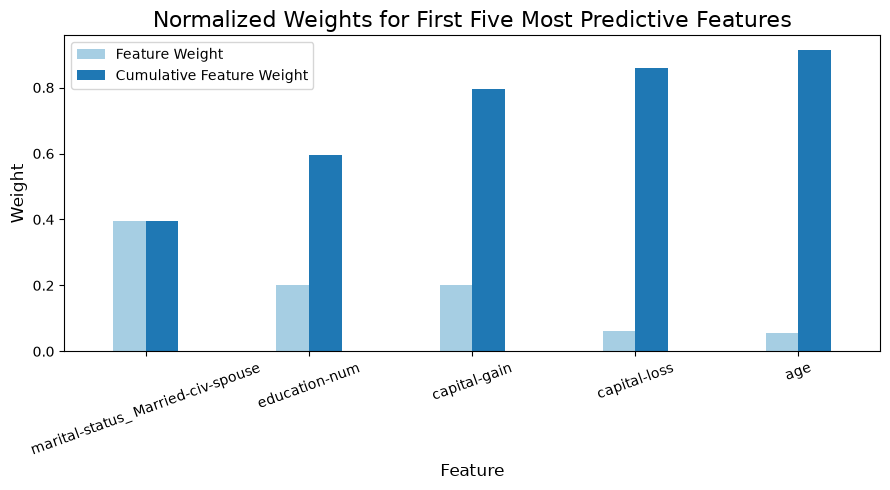

In [12]:
# TODO: Import a supervised learning model that has 'feature_importances_'
from sklearn.ensemble import GradientBoostingClassifier

# TODO: Train the supervised model on the training set using .fit(X_train, y_train)
model = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

# TODO: Extract the feature importances using .feature_importances_
importances = model.feature_importances_

# Display the ranking of the five most important features
feature_ranking = pd.Series(importances, index = X_train.columns).sort_values(ascending = False)
print("Feature importance ranking (top 5):")
print(feature_ranking.head(5))

# Plot
vs.feature_plot(importances, X_train, y_train)


### Question 7 - Extracting Feature Importance

Observe the visualization created above which displays the five most relevant features for predicting if an individual makes at most or above $50,000.  
* How do these five features compare to the five features you discussed in **Question 6**?
* If you were close to the same answer, how does this visualization confirm your thoughts? 
* If you were not close, why do you think these features are more relevant?

**Answer:**

The five most important features reported by the Gradient Boosting Classifier (with their normalized weights) are:

| Rank | Model's feature | Weight | My rank in Q6 |
| :--: | :-------------- | :----: | :-----------: |
| 1 | marital-status_ Married-civ-spouse | 0.3940 | not in top 5 |
| 2 | education-num | 0.2017 | 3rd |
| 3 | capital-gain | 0.2000 | 1st |
| 4 | capital-loss | 0.0627 | not in top 5 |
| 5 | age | 0.0543 | 2nd |

These five features together account for roughly 91% of the total importance, which confirms the observation from the plot that a handful of features dominate the prediction.

**Comparison with Question 6:** I correctly predicted 3 of the 5 features - `capital-gain`, `age` and `education-num` all made the list, and `education-num` and `capital-gain` are ranked 2nd and 3rd, very close to where I placed them. My 4th and 5th choices, `hours-per-week` and `occupation`, did not make the top five; instead the model selected `marital-status_ Married-civ-spouse` and `capital-loss`.

**What surprised me:** First, `marital-status_ Married-civ-spouse` is by far the most important feature (weight 0.39, nearly double the runner-up), which I did not expect at all. On reflection the correlation is obvious for this 1994 census: married people with a civilian spouse are typically in their prime earning years and often form dual-income households, and the marital-status column is strongly correlated with age and full-time employment, so the model can use it as a proxy for several effects at once. Second, I expected `capital-gain` to be ranked #1 as it usually is for this dataset, but it came 3rd - its signal is concentrated in the small fraction of records with a non-zero gain, while `capital-gain` and `capital-loss` are zero for the vast majority of people, so the model spreads that financial signal across several related columns. Third, `capital-loss` appearing at #4 was completely unexpected, though it is the natural companion of `capital-gain` (people who realize losses are usually wealthy enough to hold investments). Finally, `occupation` was diluted because one-hot encoding split it into 14 separate binary columns, so its total importance is spread across columns rather than concentrated in one. One caveat worth noting is that tree-based `feature_importances_` measures the average reduction in impurity and is biased toward features with many possible split points (e.g. the multi-category marital-status column), so its ranking should be read as "what this model used" rather than pure causal importance.


### Feature Selection
How does a model perform if we only use a subset of all the available features in the data? With less features required to train, the expectation is that training and prediction time is much lower — at the cost of performance metrics. From the visualization above, we see that the top five most important features contribute more than half of the importance of **all** features present in the data. This hints that we can attempt to *reduce the feature space* and simplify the information required for the model to learn. The code cell below will use the same optimized model you found earlier, and train it on the same training set *with only the top five important features*. 

In [13]:
# Import functionality for cloning a model
from sklearn.base import clone

# Reduce the feature space
X_train_reduced = X_train[X_train.columns.values[(np.argsort(importances)[::-1])[:5]]]
X_test_reduced = X_test[X_test.columns.values[(np.argsort(importances)[::-1])[:5]]]

# Train on the "best" model found from grid search earlier
clf = (clone(best_clf)).fit(X_train_reduced, y_train)

# Make new predictions
reduced_predictions = clf.predict(X_test_reduced)

# Report scores from the final model using both versions of data
print("Final Model trained on full data\n------")
print("Accuracy on testing data: {:.4f}".format(accuracy_score(y_test, best_predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, best_predictions, beta = 0.5)))
print("\nFinal Model trained on reduced data\n------")
print("Accuracy on testing data: {:.4f}".format(accuracy_score(y_test, reduced_predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, reduced_predictions, beta = 0.5)))

Final Model trained on full data
------
Accuracy on testing data: 0.8706
F-score on testing data: 0.7516

Final Model trained on reduced data
------
Accuracy on testing data: 0.8590
F-score on testing data: 0.7252


### Question 8 - Effects of Feature Selection

* How does the final model's F-score and accuracy score on the reduced data using only five features compare to those same scores when all features are used?
* If training time was a factor, would you consider using the reduced data as your training set?

**Answer:**

Using only the top five features, the final (grid-searched) model scores an **accuracy of 0.8590** and an **F-score of 0.7252** on the test data, compared with **0.8706** accuracy and **0.7516** F-score when all 103 features are used. So dropping from 103 features to 5 - a 95% reduction in the feature space - costs about 1.16 percentage points of accuracy and 2.64 percentage points of F-score (a ~3.5% relative drop in F-score). That is a remarkably small price to pay, and it makes sense given the importance plot: the top five features carry roughly 91% of the model's total importance, so most of the predictive signal is retained while the remaining 98 columns mostly add noise and redundancy.

**If training time were a factor, would I use the reduced data?** On this particular dataset I would still keep all features, because training is already fast (the full gradient boosting model trains in about 5 seconds, and even the whole grid search completes in minutes), so the speed-up from using 5 features would save little while giving up a noticeable slice of F-score - and for CharityML the F-score is the metric that directly controls how many wasted letters go to non-donors. However, if the problem grew to millions of records, if the model had to be retrained frequently (e.g. nightly), or if collecting all 103 encoded columns were expensive or error-prone in a production pipeline, the reduced model would be an attractive trade-off: it trains and scores several times faster, is far simpler to maintain and explain to non-technical stakeholders, and still gives up only ~2.6 points of F-score. In short: full features for maximum accuracy when compute is cheap, reduced features when speed, memory or simplicity matter more than the last few points of performance.


> **Note**: Once you have completed all of the code implementations and successfully answered each question above, you may finalize your work by exporting the iPython Notebook as an HTML document. You can do this by using the menu above and navigating to  
**File -> Download as -> HTML (.html)**. Include the finished document along with this notebook as your submission.